# Cambodia Food Price Analysis & 3-Month Forecast

**Time-Series Data Analysis — Final Project**

**Data:** WFP Food Prices for Cambodia (`wfp_food_prices_khm.csv`), 2003-01 .. 2026-09

**Goal:** Understand price behaviour (trend, seasonality, stationarity, autocorrelation)
and forecast the next 3 months (Oct, Nov, Dec 2026) nationally and by province.

Run cells top-to-bottom. Each cell prints or plots its result.


## Install packages

Run this once if needed.


In [5]:
%pip install -q numpy pandas matplotlib seaborn scipy statsmodels


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Imports & settings


In [6]:
import itertools
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

%matplotlib inline
warnings.filterwarnings("ignore")

In [8]:
HERE = Path.cwd()
DATA = HERE / "wfp_food_prices_khm.csv"
FIG = HERE / "figures"
OUT = HERE / "outputs"
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "savefig.bbox": "tight"})

H = 3
M = 12
Z80, Z95 = 1.2816, 1.96

print("Ready.")
print("Data file:", DATA)
print("Exists:", DATA.exists())


Ready.
Data file: /Users/cheamenghour/Documents/AUPP/Time series/final_project/wfp_food_prices_khm.csv
Exists: True


## 2. Load the raw data


In [9]:
df = pd.read_csv(DATA, parse_dates=["date"])
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

print(f"Rows: {len(df):,}")
print(f"Date range: {df.date.min():%Y-%m} -> {df.date.max():%Y-%m}")
print(f"Provinces: {df.admin1.nunique()}")
print(f"Markets: {df.market.nunique()}")
print(f"Commodities: {df.commodity.nunique()}")
df.head()


Rows: 91,682
Date range: 2003-01 -> 2026-09
Provinces: 25
Markets: 86
Commodities: 50


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month
0,2003-01-15,Banteay Meanchey,Serei Saophoan,Banteay Meanchey,640,13.59,102.96,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Wholesale,KHR,845.0,0.22,2003-01-01
1,2003-01-15,Battambang,Battambang,Battambang,639,13.10,103.20,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Wholesale,KHR,500.0,0.13,2003-01-01
2,2003-01-15,Kampong Cham,Kampong Cham,Kampong Cham,633,11.99,105.46,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Wholesale,KHR,575.0,0.15,2003-01-01
3,2003-01-15,Kampong Chhnang,Kampong Chhnang,Kampong Chhnang,632,12.25,104.67,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Wholesale,KHR,710.0,0.19,2003-01-01
4,2003-01-15,Kampot,Kampot,Kampot,638,10.62,104.18,cereals and tubers,"Rice (mixed, low quality)",165,KG,actual,Wholesale,KHR,770.0,0.20,2003-01-01


## 3. Dataset overview


In [10]:
overview = pd.DataFrame({
    "rows": [len(df)],
    "start": [df.date.min().date()],
    "end": [df.date.max().date()],
    "provinces": [df.admin1.nunique()],
    "markets": [df.market.nunique()],
    "commodities": [df.commodity.nunique()],
    "categories": [df.category.nunique()],
})
overview.to_csv(OUT / "00_dataset_overview.csv", index=False)
print("Dataset overview:")
display(overview)

cats = df.groupby("category").agg(
    rows=("price", "size"),
    commodities=("commodity", "nunique"),
).sort_values("rows", ascending=False)
cats.to_csv(OUT / "00_categories.csv")
print("\nBy category:")
display(cats)


Dataset overview:


,rows,start,end,provinces,markets,commodities,categories
0,91682,2003-01-15,2026-09-15,25,86,50,8



By category:


,rows,commodities
category,,
vegetables and fruits,40369,28
"meat, fish and eggs",26860,10
cereals and tubers,8381,2
miscellaneous food,6244,3
oil and fats,3817,1
pulses and nuts,3797,4
non-food,1477,1
milk and dairy,737,1


saved figures/01_data_coverage_heatmap.png


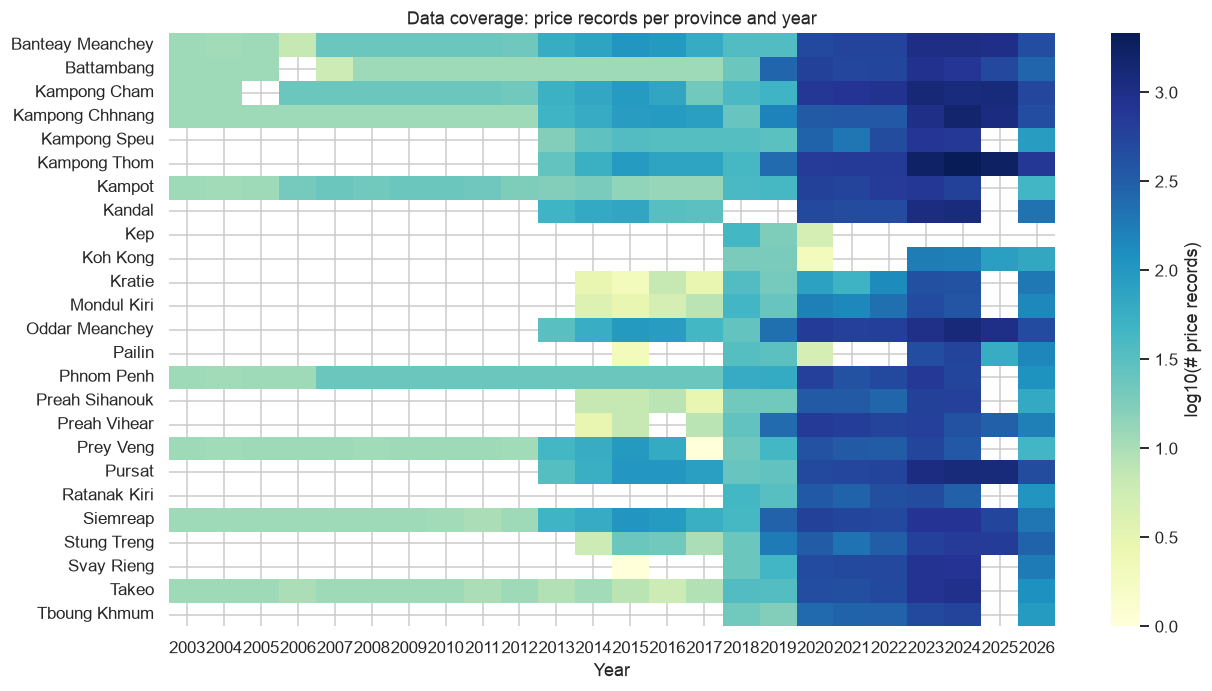

In [11]:
cov = df.groupby([df.date.dt.year, "admin1"]).size().unstack(fill_value=0).T

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(
    np.log10(cov.replace(0, np.nan)),
    cmap="YlGnBu",
    ax=ax,
    cbar_kws={"label": "log10(# price records)"},
)
ax.set(title="Data coverage: price records per province and year", xlabel="Year", ylabel="")
fig.savefig(FIG / "01_data_coverage_heatmap.png")
print("saved figures/01_data_coverage_heatmap.png")
plt.show()


## 4. Build national wholesale rice series


In [12]:
# Wholesale rice (mixed, low quality), KG
# Several markets per province -> median market price per province-month
# National series = median across provinces; missing months linearly interpolated

rice = df[
    (df.commodity == "Rice (mixed, low quality)")
    & (df.pricetype == "Wholesale")
    & (df.unit == "KG")
]
prov_rice = rice.pivot_table(index="month", columns="admin1", values="price", aggfunc="median")

y = prov_rice.median(axis=1)
idx = pd.date_range(y.index.min(), y.index.max(), freq="MS")
y = y.reindex(idx)
imp = y.isna()
y = y.interpolate("time")
y.index.freq = "MS"
y.name = "Rice (mixed, low quality)"
obs = ~imp

print(f"Months: {len(y)}")
print(f"Imputed months ({imp.sum()}): {[d.strftime('%Y-%m') for d in y.index[imp]]}")
y.to_frame("price_khr_per_kg").assign(imputed=imp).to_csv(OUT / "01_rice_wholesale_national.csv")
y.to_frame("price_khr_per_kg").assign(imputed=imp).tail(12)


Months: 285
Imputed months (6): ['2025-01', '2025-02', '2026-04', '2026-05', '2026-07', '2026-08']


,price_khr_per_kg,imputed
2025-10-01,1700.000000,False
2025-11-01,1775.000000,False
2025-12-01,1600.000000,False
2026-01-01,1700.000000,False
2026-02-01,1675.000000,False
2026-03-01,1673.437500,False
2026-04-01,1716.083560,True
2026-05-01,1757.353940,True
2026-06-01,1800.000000,False
2026-07-01,1832.608696,True


saved figures/02_rice_wholesale_timeseries.png


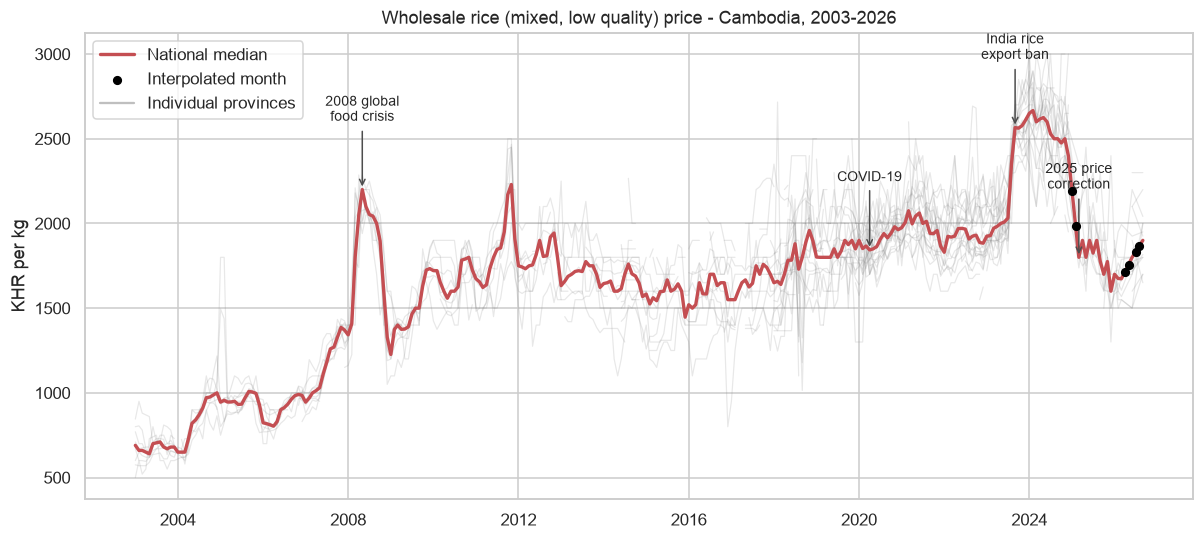

In [13]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for c in prov_rice.columns:
    ax.plot(prov_rice.index, prov_rice[c], color="grey", alpha=0.18, lw=0.8)
ax.plot(y.index, y, color="C3", lw=2.2, label="National median")
ax.scatter(y.index[imp], y[imp], color="black", zorder=5, s=25, label="Interpolated month")

events = [
    ("2008-05-01", "2008 global\nfood crisis"),
    ("2020-04-01", "COVID-19"),
    ("2023-09-01", "India rice\nexport ban"),
    ("2025-03-01", "2025 price\ncorrection"),
]
for d, txt in events:
    ax.annotate(
        txt,
        (pd.Timestamp(d), y.asof(pd.Timestamp(d))),
        xytext=(0, 45),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        arrowprops=dict(arrowstyle="->", color="0.3"),
    )

ax.set(
    title="Wholesale rice (mixed, low quality) price - Cambodia, 2003-2026",
    ylabel="KHR per kg",
    xlabel="",
)
ax.plot([], [], color="grey", alpha=0.5, label="Individual provinces")
ax.legend(loc="upper left")
fig.savefig(FIG / "02_rice_wholesale_timeseries.png")
print("saved figures/02_rice_wholesale_timeseries.png")
plt.show()


## 5. Descriptive statistics & histograms


In [14]:
recent = y["2019":]
mom = (y.pct_change() * 100).dropna()

desc = pd.DataFrame({
    "Price level 2003-2026": y.describe(),
    "Price level 2019-2026": recent.describe(),
    "Monthly % change": mom.describe(),
}).T
desc["median"] = [y.median(), recent.median(), mom.median()]
desc["mode_bin"] = [pd.cut(s, 20).value_counts().idxmax().mid for s in (y, recent, mom)]
desc["skew"] = [stats.skew(s) for s in (y, recent, mom)]
desc["kurtosis"] = [stats.kurtosis(s) for s in (y, recent, mom)]
desc.round(2).to_csv(OUT / "02_descriptive_stats.csv")
print("Descriptive statistics:")
display(desc.round(2))


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max,median,mode_bin,skew,kurtosis
Price level 2003-2026,285.0,1630.26,453.14,640.00,1500.00,1702.00,1900.00,2666.50,1702.00,1703.91,-0.40,0.07
Price level 2019-2026,93.0,2010.86,274.48,1600.00,1850.00,1925.00,2008.81,2666.50,1925.00,1946.61,1.27,0.37
Monthly % change,284.0,0.46,4.62,-17.01,-1.48,0.39,2.39,27.89,0.39,-0.17,0.51,5.65


saved figures/03_histograms.png


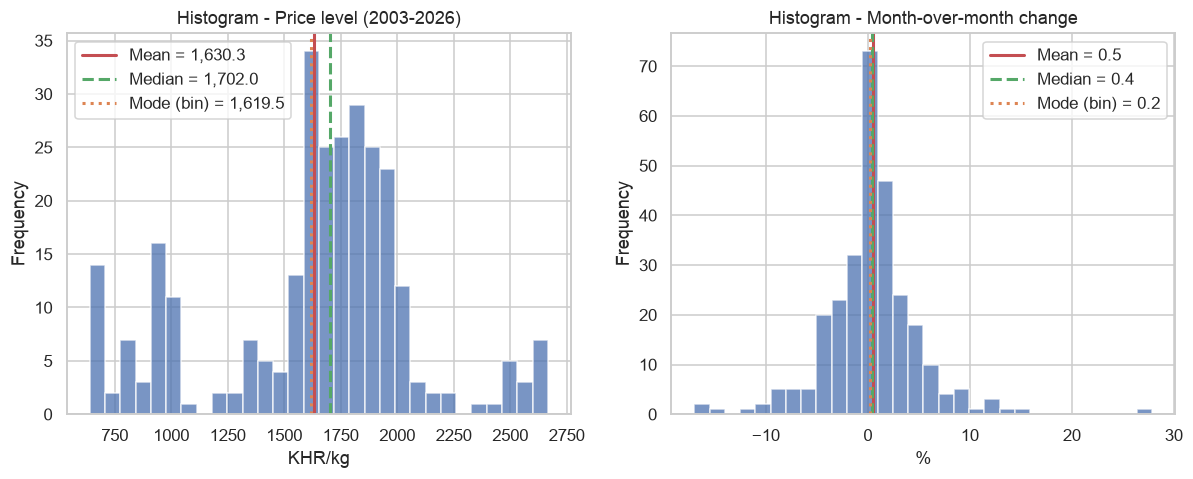

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.hist(y, bins=30, color="C0", alpha=0.75, edgecolor="white")
ax.axvline(y.mean(), color="C3", lw=2, label=f"Mean = {y.mean():,.1f}")
ax.axvline(y.median(), color="C2", lw=2, ls="--", label=f"Median = {y.median():,.1f}")
mode = pd.cut(y, 30).value_counts().idxmax().mid
ax.axvline(mode, color="C1", lw=2, ls=":", label=f"Mode (bin) = {mode:,.1f}")
ax.set(title="Histogram - Price level (2003-2026)", xlabel="KHR/kg", ylabel="Frequency")
ax.legend()

ax = axes[1]
ax.hist(mom, bins=30, color="C0", alpha=0.75, edgecolor="white")
ax.axvline(mom.mean(), color="C3", lw=2, label=f"Mean = {mom.mean():,.1f}")
ax.axvline(mom.median(), color="C2", lw=2, ls="--", label=f"Median = {mom.median():,.1f}")
mode = pd.cut(mom, 30).value_counts().idxmax().mid
ax.axvline(mode, color="C1", lw=2, ls=":", label=f"Mode (bin) = {mode:,.1f}")
ax.set(title="Histogram - Month-over-month change", xlabel="%", ylabel="Frequency")
ax.legend()

fig.savefig(FIG / "03_histograms.png")
print("saved figures/03_histograms.png")
plt.show()


## 6. Boxplots by month and province


saved figures/04_boxplot_by_month.png


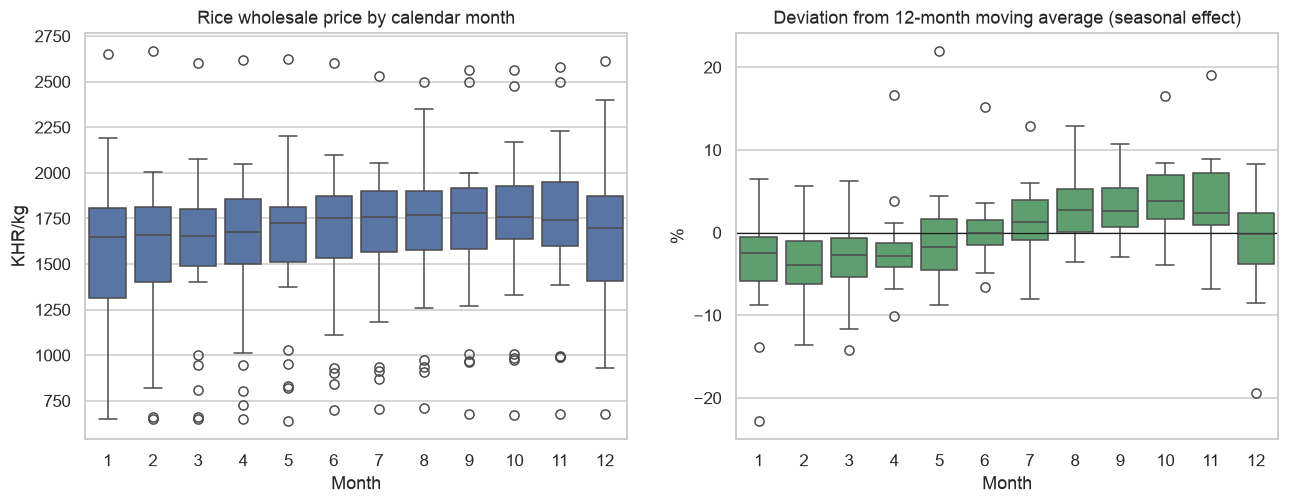

In [16]:
by_month = pd.DataFrame({"price": y, "month": y.index.month, "year": y.index.year})
by_month["detrended_%"] = 100 * (y / y.rolling(12, center=True, min_periods=6).mean() - 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=by_month, x="month", y="price", ax=axes[0], color="C0")
axes[0].set(title="Rice wholesale price by calendar month", xlabel="Month", ylabel="KHR/kg")
sns.boxplot(data=by_month, x="month", y="detrended_%", ax=axes[1], color="C2")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Deviation from 12-month moving average (seasonal effect)", xlabel="Month", ylabel="%")
fig.savefig(FIG / "04_boxplot_by_month.png")
print("saved figures/04_boxplot_by_month.png")
plt.show()


saved figures/05_boxplot_by_province.png


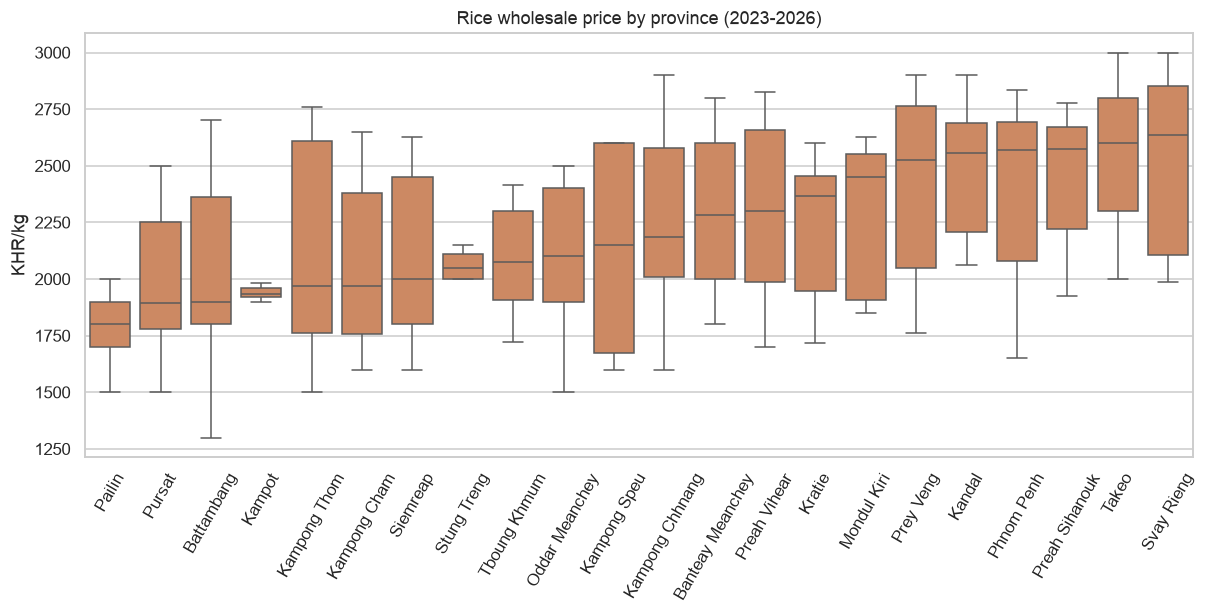

In [17]:
rp = prov_rice["2023":].melt(ignore_index=False, var_name="province", value_name="price").dropna()
order = rp.groupby("province").price.median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=rp, x="province", y="price", order=order, ax=ax, color="C1")
ax.set(title="Rice wholesale price by province (2023-2026)", xlabel="", ylabel="KHR/kg")
ax.tick_params(axis="x", rotation=60)
fig.savefig(FIG / "05_boxplot_by_province.png")
print("saved figures/05_boxplot_by_province.png")
plt.show()


## 7. Classical & STL decomposition


saved figures/06_classical_decomposition.png


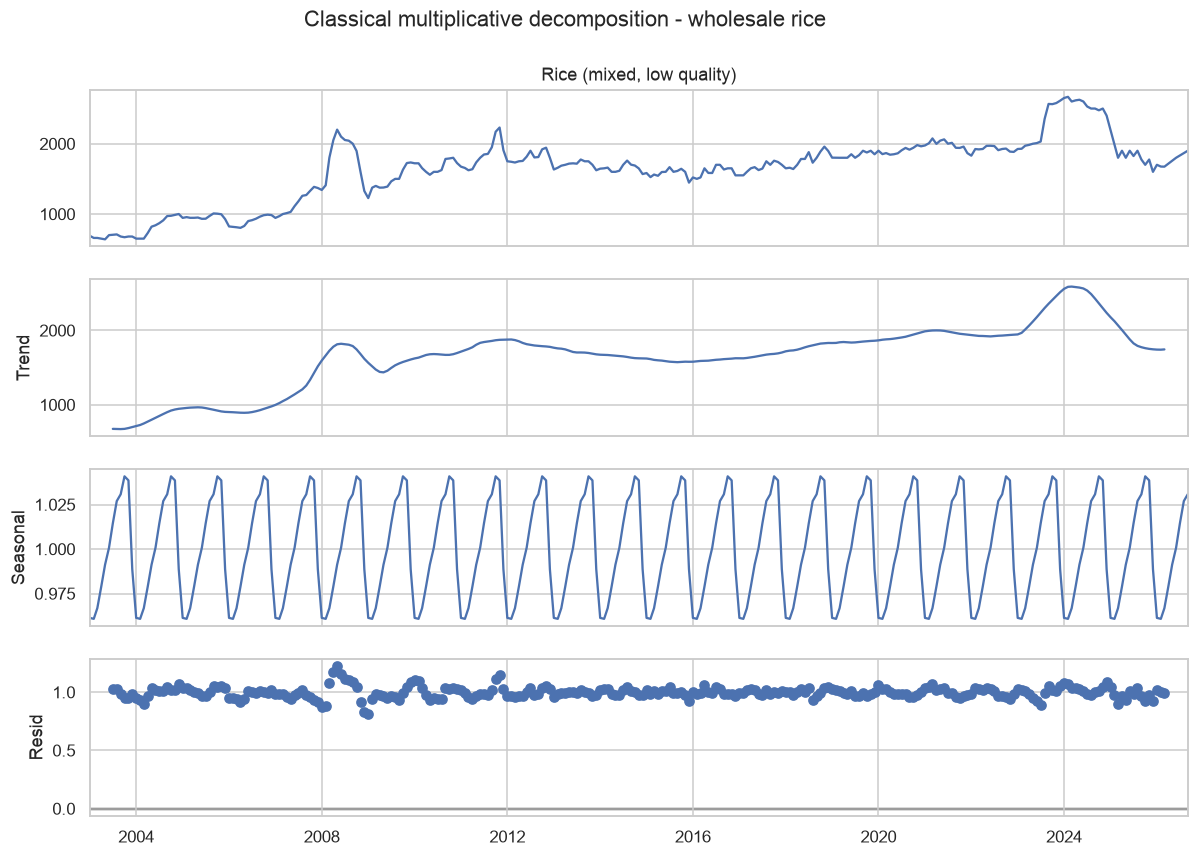

In [18]:
dec = seasonal_decompose(y, model="multiplicative", period=M)
fig = dec.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Classical multiplicative decomposition - wholesale rice", y=1.01)
fig.savefig(FIG / "06_classical_decomposition.png")
print("saved figures/06_classical_decomposition.png")
plt.show()


saved figures/07_stl_decomposition.png


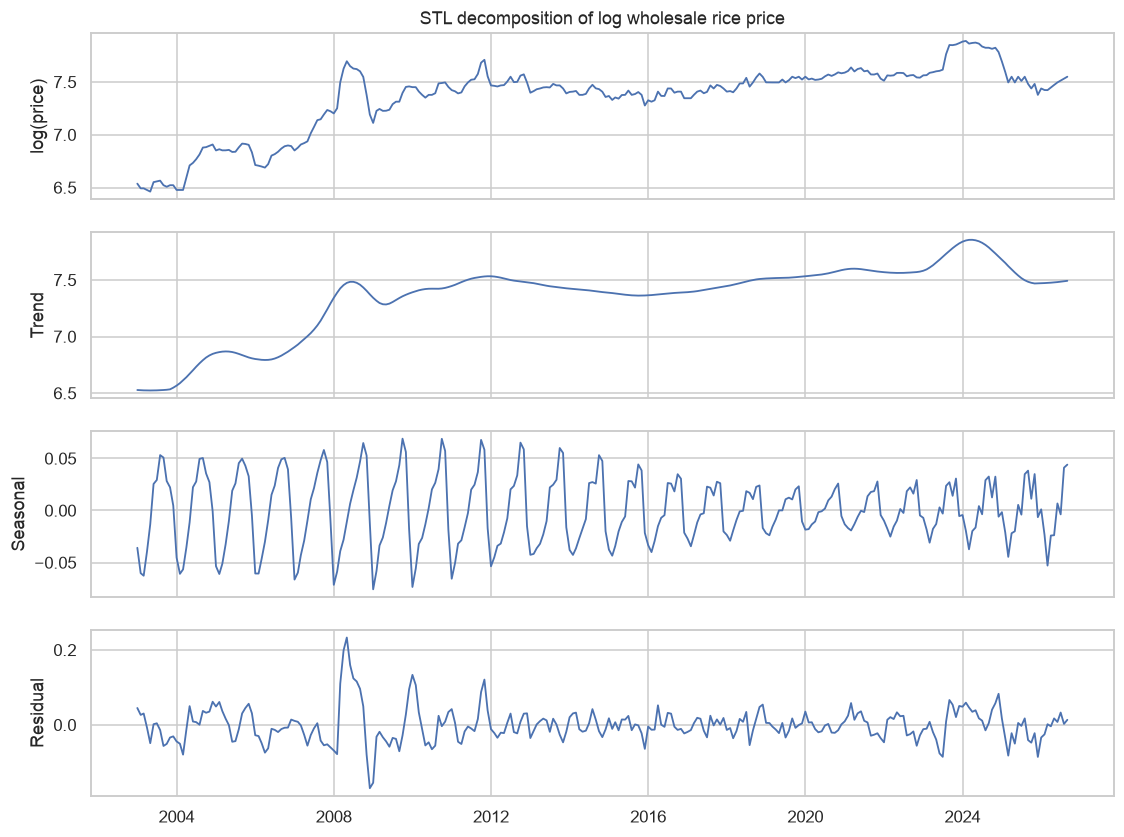

Trend / seasonal strength:


trend_strength       0.981
seasonal_strength    0.351
dtype: float64


Seasonal index (%):


,seasonal_index_%
1,-3.87
2,-3.92
3,-3.32
4,-2.11
5,-0.88
6,0.07
7,1.44
8,2.69
9,3.08
10,4.08


In [19]:
stl = STL(np.log(y), period=M, seasonal=13).fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(np.log(y), lw=1.2)
axes[0].set_ylabel("log(price)")
axes[0].set_title("STL decomposition of log wholesale rice price")
axes[1].plot(stl.trend, lw=1.2)
axes[1].set_ylabel("Trend")
axes[2].plot(stl.seasonal, lw=1.2)
axes[2].set_ylabel("Seasonal")
axes[3].plot(stl.resid, lw=1.2)
axes[3].set_ylabel("Residual")
fig.savefig(FIG / "07_stl_decomposition.png")
print("saved figures/07_stl_decomposition.png")
plt.show()

var_r = np.var(stl.resid)
strength = {
    "trend_strength": max(0, 1 - var_r / np.var(stl.trend + stl.resid)),
    "seasonal_strength": max(0, 1 - var_r / np.var(stl.seasonal + stl.resid)),
}
seas_idx = (dec.seasonal[:12].groupby(dec.seasonal[:12].index.month).mean() - 1) * 100
pd.DataFrame({"seasonal_index_%": seas_idx}).round(2).to_csv(OUT / "03_seasonal_index.csv")
pd.Series(strength).round(3).to_csv(OUT / "03_trend_seasonal_strength.csv")
print("Trend / seasonal strength:")
display(pd.Series(strength).round(3))
print("\nSeasonal index (%):")
display(pd.DataFrame({"seasonal_index_%": seas_idx}).round(2))


saved figures/08_seasonal_plot.png


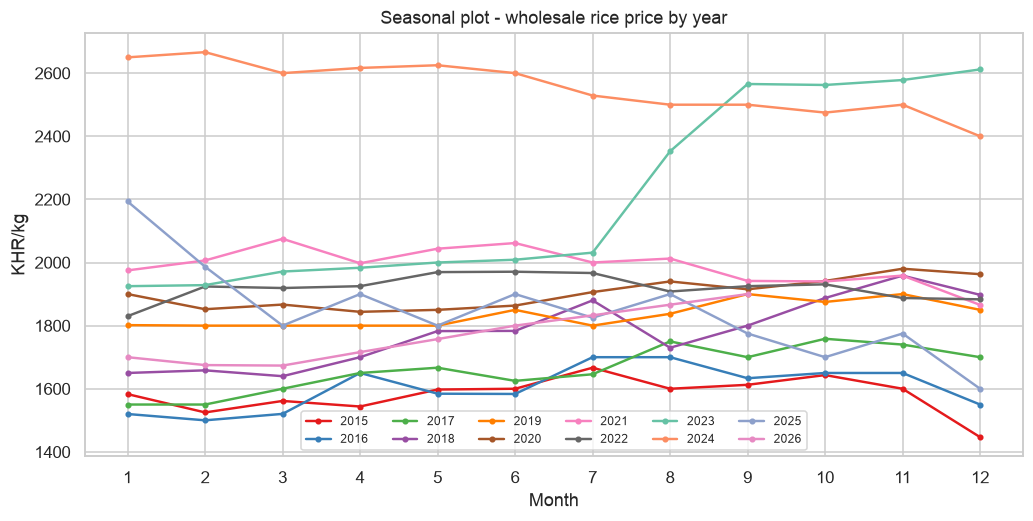

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
years = range(2015, 2027)
# High-contrast qualitative colors (easy to tell years apart)
colors = [
    "#e41a1c", "#377eb8", "#4daf4a", "#984ea3",
    "#ff7f00", "#a65628", "#f781bf", "#666666",
    "#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3",
]
for i, yr in enumerate(years):
    s = y[str(yr)]
    ax.plot(s.index.month, s.values, color=colors[i], lw=1.6, marker="o", ms=3, label=str(yr))
ax.set(
    title="Seasonal plot - wholesale rice price by year",
    xlabel="Month",
    ylabel="KHR/kg",
    xticks=range(1, 13),
)
ax.legend(ncol=6, fontsize=8)
fig.savefig(FIG / "08_seasonal_plot.png")
print("saved figures/08_seasonal_plot.png")
plt.show()


## 8. Scatterplots & commodity correlations


saved figures/09_scatterplots.png


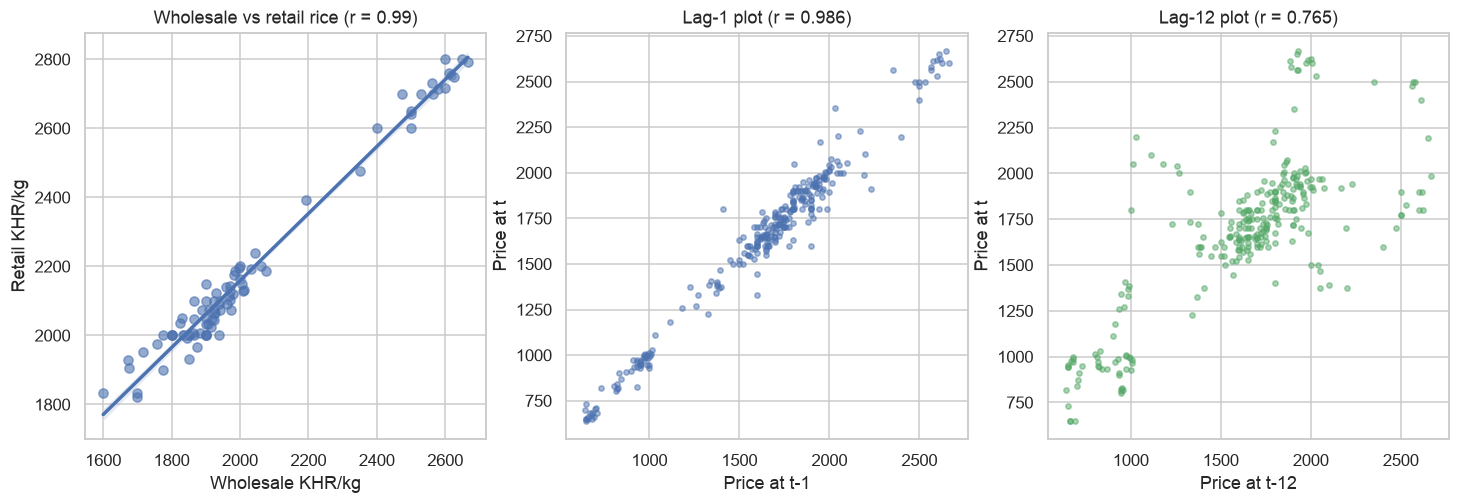

In [22]:
# Retail rice for comparison with wholesale
retail_raw = df[
    (df.commodity == "Rice (mixed, low quality)")
    & (df.pricetype == "Retail")
    & (df.unit == "KG")
]
retail_prov = retail_raw.pivot_table(index="month", columns="admin1", values="price", aggfunc="median")
retail_rice = retail_prov.median(axis=1)
ridx = pd.date_range(retail_rice.index.min(), retail_rice.index.max(), freq="MS")
retail_rice = retail_rice.reindex(ridx).interpolate("time")
retail_rice.index.freq = "MS"

both = pd.concat({"wholesale": y, "retail": retail_rice}, axis=1).dropna()["2019-08":]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.regplot(x=both.wholesale, y=both.retail, ax=axes[0], scatter_kws=dict(alpha=0.6))
r = both.corr().iloc[0, 1]
axes[0].set(title=f"Wholesale vs retail rice (r = {r:.2f})", xlabel="Wholesale KHR/kg", ylabel="Retail KHR/kg")
axes[1].scatter(y.shift(1), y, alpha=0.5, s=12)
axes[1].set(title=f"Lag-1 plot (r = {y.autocorr(1):.3f})", xlabel="Price at t-1", ylabel="Price at t")
axes[2].scatter(y.shift(12), y, alpha=0.5, s=12, color="C2")
axes[2].set(title=f"Lag-12 plot (r = {y.autocorr(12):.3f})", xlabel="Price at t-12", ylabel="Price at t")
fig.savefig(FIG / "09_scatterplots.png")
print("saved figures/09_scatterplots.png")
plt.show()


Retail basket shape: (86, 8)


,Rice,Pork,Snakehead fish,Duck eggs,Vegetable oil,Salt,Water spinach,Wax gourd
2026-05-01,1975.959837,18720.957880,9852.581522,4708.848505,31241.847826,1450.000000,3146.059783,2745.923913
2026-06-01,2000.000000,19000.000000,10000.000000,5000.000000,32000.000000,1450.000000,3125.000000,3125.000000
2026-07-01,2000.000000,18673.913043,10326.086957,5000.000000,32000.000000,1466.304348,3084.239130,3043.478261
2026-08-01,2000.000000,18336.956522,10663.043478,5000.000000,32000.000000,1483.152174,3042.119565,2959.239130
2026-09-01,2000.000000,18000.000000,11000.000000,5000.000000,32000.000000,1500.000000,3000.000000,2875.000000


saved figures/10_commodity_correlation.png


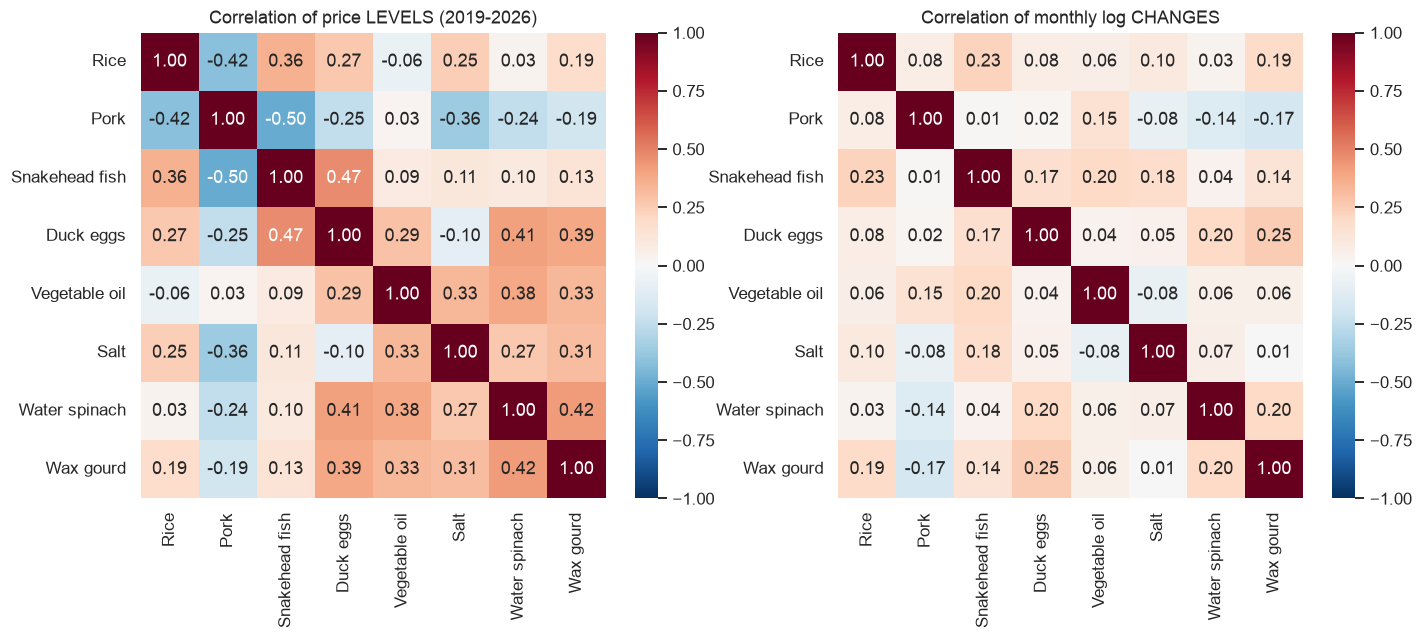

In [23]:
# Build 8-commodity retail basket (from 2019-08)
BASKET = [
    ("Rice (mixed, low quality)", "Retail", "KG", "Rice"),
    ("Meat (pork, with fat)", "Retail", "KG", "Pork"),
    ("Fish (snake head)", "Retail", "KG", "Snakehead fish"),
    ("Eggs (duck)", "Retail", "10 pcs", "Duck eggs"),
    ("Oil (vegetable)", "Retail", "5 L", "Vegetable oil"),
    ("Salt (iodised)", "Retail", "KG", "Salt"),
    ("Water spinach", "Retail", "KG", "Water spinach"),
    ("Wax gourd", "Retail", "KG", "Wax gourd"),
]
BASKET_START = "2019-08-01"

nat = {}
nat_imp = {}
for com, pt, unit, short in BASKET:
    sub = df[(df.commodity == com) & (df.pricetype == pt) & (df.unit == unit)]
    pm = sub.pivot_table(index="month", columns="admin1", values="price", aggfunc="median")
    s = pm.median(axis=1)[BASKET_START:]
    idx = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    s = s.reindex(idx)
    imputed = s.isna()
    s = s.interpolate("time")
    s.index.freq = "MS"
    nat[short] = s
    nat_imp[short] = imputed

P = pd.DataFrame(nat)
P_imp = pd.DataFrame(nat_imp)
print("Retail basket shape:", P.shape)
display(P.tail())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(P.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation of price LEVELS (2019-2026)")
sns.heatmap(np.log(P).diff().corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation of monthly log CHANGES")
fig.savefig(FIG / "10_commodity_correlation.png")
print("saved figures/10_commodity_correlation.png")
plt.show()


## 9. Stationarity tests, differencing, ACF/PACF


In [24]:
ly = np.log(y)

series_list = [
    ("Original price", y),
    ("log(price)", ly),
    ("1st difference of log", ly.diff()),
    ("Seasonal difference (lag 12) of log", ly.diff(M)),
    ("1st + seasonal difference of log", ly.diff().diff(M)),
]

rows = []
for label, s in series_list:
    s2 = s.dropna()
    adf = adfuller(s2, autolag="AIC")
    kp = kpss(s2, regression="c", nlags="auto")
    rows.append({
        "series": label,
        "ADF_stat": adf[0],
        "ADF_p": adf[1],
        "ADF_verdict": "stationary" if adf[1] < 0.05 else "non-stationary",
        "KPSS_stat": kp[0],
        "KPSS_p": kp[1],
        "KPSS_verdict": "stationary" if kp[1] >= 0.05 else "non-stationary",
    })

st = pd.DataFrame(rows)
st.round(4).to_csv(OUT / "04_stationarity_tests.csv", index=False)
print("Stationarity tests:")
display(st[["series", "ADF_p", "ADF_verdict", "KPSS_p", "KPSS_verdict"]])


Stationarity tests:


,series,ADF_p,ADF_verdict,KPSS_p,KPSS_verdict
0,Original price,1.082549e-01,non-stationary,0.010000,non-stationary
1,log(price),7.291843e-02,non-stationary,0.010000,non-stationary
2,1st difference of log,7.014081e-23,stationary,0.100000,stationary
3,Seasonal difference (lag 12) of log,8.587942e-04,stationary,0.090688,stationary
4,1st + seasonal difference of log,1.535170e-05,stationary,0.100000,stationary


saved figures/11_differencing.png


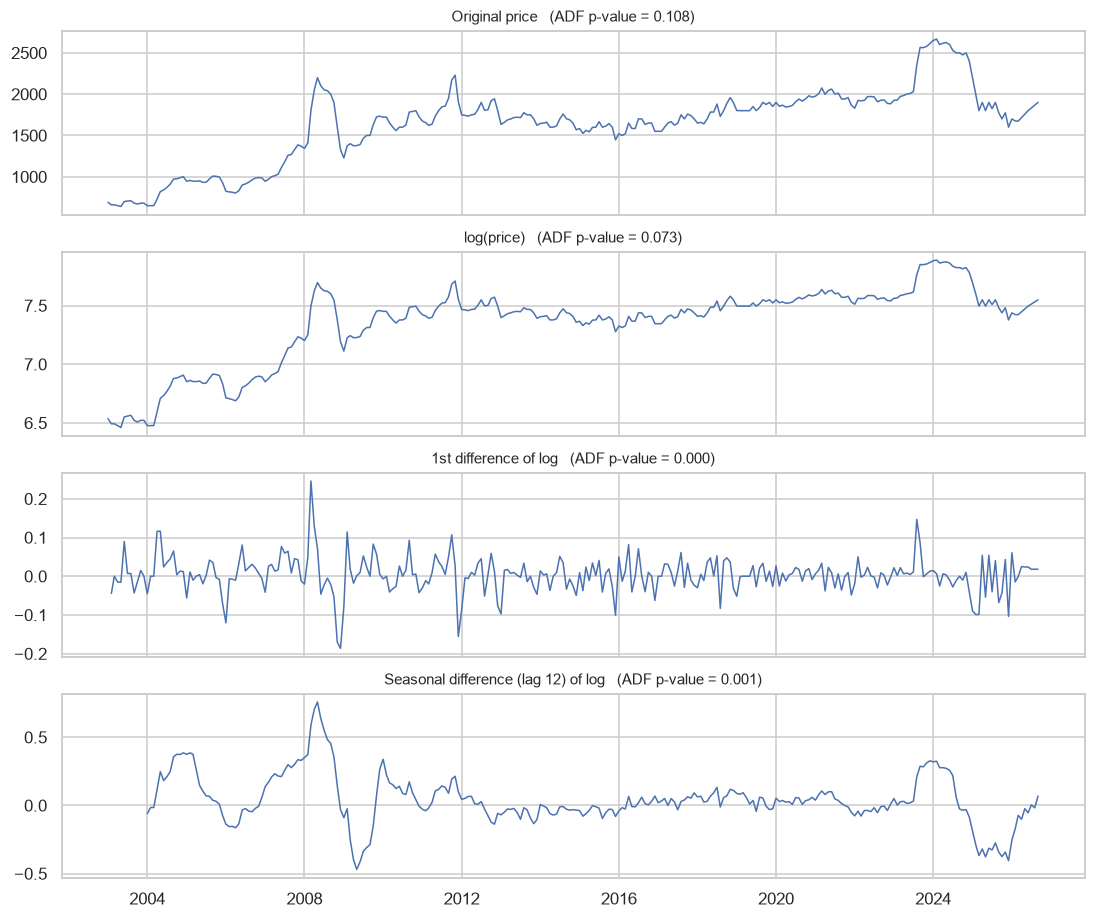

In [25]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (k, s) in zip(axes, series_list[:4]):
    p = st.set_index("series").loc[k, "ADF_p"]
    ax.plot(s, lw=1)
    ax.set_title(f"{k}   (ADF p-value = {p:.3f})", fontsize=10)
fig.savefig(FIG / "11_differencing.png")
print("saved figures/11_differencing.png")
plt.show()


saved figures/12_acf_pacf.png


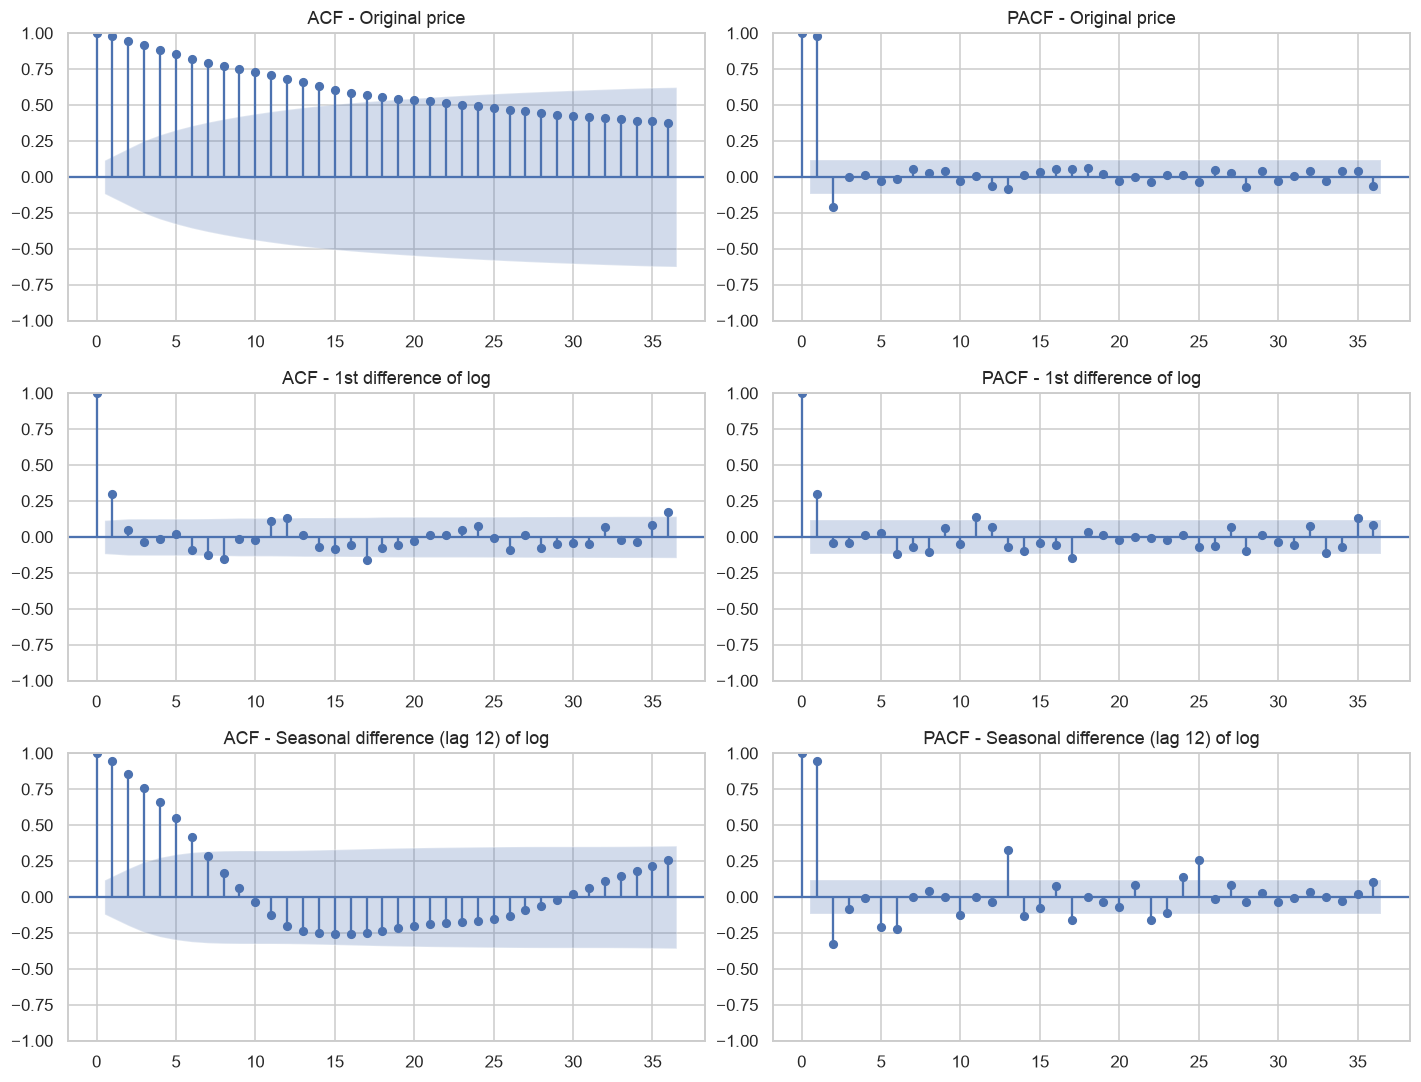

Ljung-Box on 1st difference of log:


,lb_stat,lb_pvalue
1,25.9597,0.0
3,27.0668,0.0
6,29.7906,0.0
12,50.2502,0.0
24,68.2293,0.0


In [26]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
pairs = [
    ("Original price", y),
    ("1st difference of log", ly.diff()),
    ("Seasonal difference (lag 12) of log", ly.diff(M)),
]
for row, (k, s) in enumerate(pairs):
    plot_acf(s.dropna(), lags=36, ax=axes[row, 0], title=f"ACF - {k}")
    plot_pacf(s.dropna(), lags=36, ax=axes[row, 1], method="ywm", title=f"PACF - {k}")
fig.tight_layout()
fig.savefig(FIG / "12_acf_pacf.png")
print("saved figures/12_acf_pacf.png")
plt.show()

lb = acorr_ljungbox(ly.diff().dropna(), lags=[1, 3, 6, 12, 24], return_df=True)
lb.round(4).to_csv(OUT / "05_ljungbox_diff.csv")
print("Ljung-Box on 1st difference of log:")
display(lb.round(4))


saved figures/13_random_walk.png


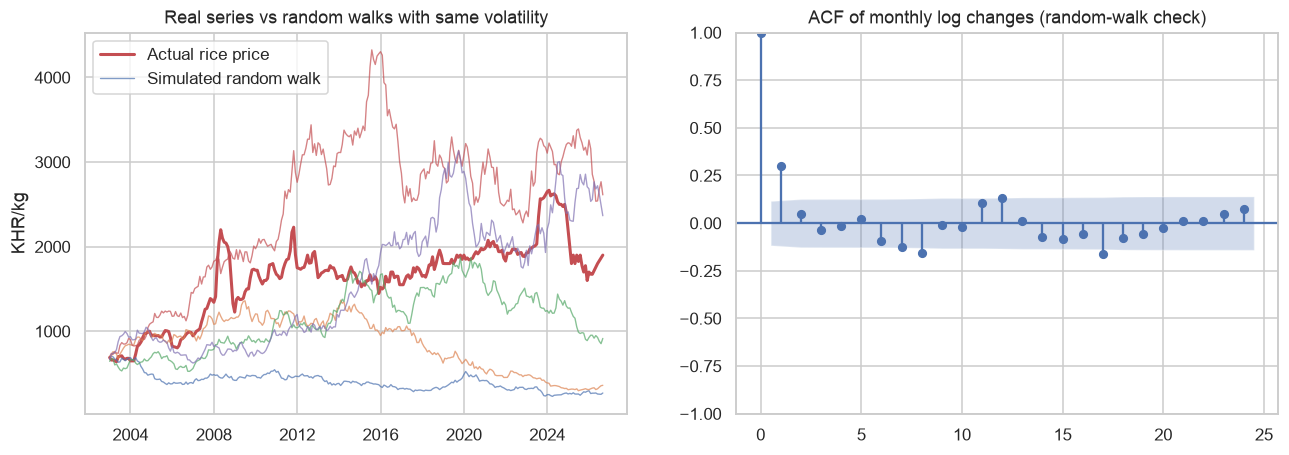

In [27]:
rng = np.random.default_rng(7)
d = ly.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(y.index, y, color="C3", lw=2, label="Actual rice price")
for k in range(5):
    sim = np.exp(ly.iloc[0] + np.cumsum(rng.normal(d.mean(), d.std(), len(y))))
    axes[0].plot(y.index, sim, lw=0.9, alpha=0.7, label="Simulated random walk" if k == 0 else None)
axes[0].set(title="Real series vs random walks with same volatility", ylabel="KHR/kg")
axes[0].legend()
plot_acf(d, lags=24, ax=axes[1], title="ACF of monthly log changes (random-walk check)")
fig.savefig(FIG / "13_random_walk.png")
print("saved figures/13_random_walk.png")
plt.show()


## 10. Hold-out forecast (train ≤ Dec 2025, test Jan–Mar 2026)

Select SARIMA by AIC, then compare several simple models. This cell may take a minute.


In [28]:
split_end = pd.Timestamp("2025-12-01")
train = y[:split_end]
test = y["2026-01-01":"2026-03-01"]
print("Train end:", train.index[-1].date(), "| Test months:", list(test.index.strftime("%Y-%m")))

# Grid search SARIMA on log prices (d=1)
print("\nSelecting SARIMA order ...")
grid_rows = []
for pp, qq, (P, D, Q) in itertools.product(
    (0, 1, 2), (0, 1, 2), ((0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1))
):
    try:
        r = SARIMAX(
            np.log(train),
            order=(pp, 1, qq),
            seasonal_order=(P, D, Q, M),
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False)
        grid_rows.append({"order": (pp, 1, qq), "sorder": (P, D, Q, M), "aic": r.aic})
    except Exception:
        pass

grid = pd.DataFrame(grid_rows).sort_values("aic").reset_index(drop=True)
order = grid.loc[0, "order"]
sorder = grid.loc[0, "sorder"]
grid.head(10).to_csv(OUT / "06_sarima_grid_top10.csv", index=False)
print(f"Best: SARIMA{order}x{sorder}  AIC={grid.aic.iloc[0]:.1f}")
display(grid.head(10))


Train end: 2025-12-01 | Test months: ['2026-01', '2026-02', '2026-03']

Selecting SARIMA order ...
Best: SARIMA(1, 1, 0)x(0, 0, 0, 12)  AIC=-931.6


,order,sorder,aic
0,"(1, 1, 0)","(0, 0, 0, 12)",-931.584147
1,"(0, 1, 1)","(0, 0, 0, 12)",-927.212391
2,"(2, 1, 0)","(0, 0, 0, 12)",-926.458761
3,"(1, 1, 1)","(0, 0, 0, 12)",-926.276347
4,"(2, 1, 1)","(0, 0, 0, 12)",-924.345454
5,"(0, 1, 2)","(0, 0, 0, 12)",-922.281228
6,"(1, 1, 2)","(0, 0, 0, 12)",-920.411489
7,"(2, 1, 2)","(0, 0, 0, 12)",-918.822959
8,"(0, 1, 0)","(0, 0, 0, 12)",-903.894689
9,"(0, 1, 1)","(1, 0, 0, 12)",-893.248072


In [29]:
# Forecasts from each model for the 3-month hold-out
fc_mean = np.repeat(train.mean(), H)
fc_naive = np.repeat(train.iloc[-1], H)
fc_snaive = np.array([train.iloc[-M + (i % M)] for i in range(H)])
slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
fc_drift = train.iloc[-1] + slope * np.arange(1, H + 1)
fc_ma3 = np.repeat(train.iloc[-3:].mean(), H)

# ETS models on log prices
ets_ses = ETSModel(np.log(train), error="add", trend=None, seasonal=None).fit(disp=False, maxiter=2000)
fc_ses = np.exp(ets_ses.forecast(H).values)

ets_holt = ETSModel(
    np.log(train), error="add", trend="add", damped_trend=True, seasonal=None
).fit(disp=False, maxiter=2000)
fc_holt = np.exp(ets_holt.forecast(H).values)

ets_hw = ETSModel(
    np.log(train), error="add", trend="add", damped_trend=True,
    seasonal="add", seasonal_periods=M,
).fit(disp=False, maxiter=2000)
fc_hw = np.exp(ets_hw.forecast(H).values)

sarima_fit = SARIMAX(
    np.log(train), order=order, seasonal_order=sorder,
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
fc_sarima = np.exp(sarima_fit.forecast(H).values)

sarima_name = f"SARIMA{order}x{sorder}"
split_fc = pd.DataFrame({
    "Mean": fc_mean,
    "Naive (last value)": fc_naive,
    "Seasonal naive": fc_snaive,
    "Drift": fc_drift,
    "Moving average (3)": fc_ma3,
    "ETS-SES": fc_ses,
    "ETS-Holt damped": fc_holt,
    "ETS-Holt-Winters damped": fc_hw,
    sarima_name: fc_sarima,
}, index=test.index)

ens_members = ["Naive (last value)", "ETS-Holt damped", sarima_name]
split_fc["Ensemble"] = split_fc[ens_members].mean(axis=1)

# Scores
score_rows = {}
for k in split_fc.columns:
    a = test.values.astype(float)
    f = split_fc[k].values.astype(float)
    e = a - f
    score_rows[k] = {
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAPE": 100 * np.mean(np.abs(e / a)),
        "Bias": np.mean(e),
    }
split_scores = pd.DataFrame(score_rows).T.sort_values("MAPE")
split_scores.round(2).to_csv(OUT / "07_holdout_scores.csv")
split_fc.assign(actual=test).round(1).to_csv(OUT / "07_holdout_forecasts.csv")
print("Hold-out scores:")
display(split_scores.round(2))
print("\nHold-out forecasts:")
display(split_fc.assign(actual=test).round(1))


Hold-out scores:


,MAE,RMSE,MAPE,Bias
Moving average (3),14.41,15.05,0.86,-8.85
Mean,57.07,58.36,3.39,57.07
Drift,76.19,77.59,4.52,76.19
ETS-SES,82.80,83.69,4.92,82.80
Naive (last value),82.81,83.70,4.92,82.81
Ensemble,125.83,125.90,7.48,125.83
ETS-Holt damped,146.24,146.65,8.69,146.24
"SARIMA(1, 1, 0)x(0, 0, 0, 12)",148.43,148.47,8.82,148.43
ETS-Holt-Winters damped,161.78,161.87,9.61,161.78
Seasonal naive,310.52,344.74,18.40,-310.52



Hold-out forecasts:


,Mean,Naive (last value),Seasonal naive,Drift,Moving average (3),ETS-SES,ETS-Holt damped,ETS-Holt-Winters damped,"SARIMA(1, 1, 0)x(0, 0, 0, 12)",Ensemble,actual
2026-01-01,1625.7,1600.0,2193.3,1603.3,1691.7,1600.0,1563.3,1530.6,1547.3,1570.2,1700.0
2026-02-01,1625.7,1600.0,1986.7,1606.6,1691.7,1600.0,1534.5,1516.3,1530.6,1555.0,1675.0
2026-03-01,1625.7,1600.0,1800.0,1609.9,1691.7,1600.0,1511.9,1516.2,1525.3,1545.7,1673.4


saved figures/14_holdout_forecasts.png


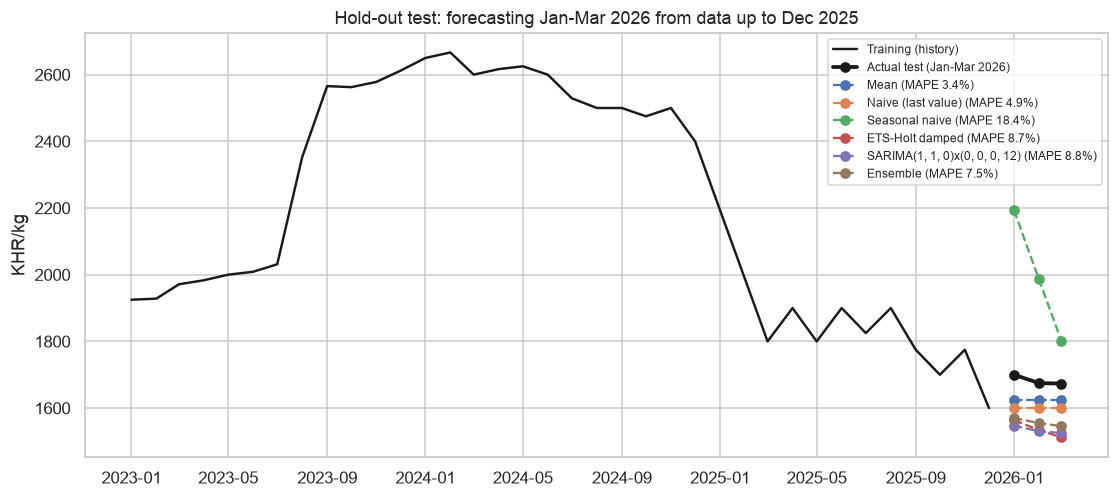

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y["2023":"2025-12"], color="k", lw=1.6, label="Training (history)")
ax.plot(test, color="k", lw=2.5, marker="o", label="Actual test (Jan-Mar 2026)")
show = ["Mean", "Naive (last value)", "Seasonal naive", "ETS-Holt damped", sarima_name, "Ensemble"]
for i, k in enumerate(show):
    ax.plot(
        test.index, split_fc[k], marker="o", ls="--", lw=1.5, color=f"C{i}",
        label=f"{k} (MAPE {split_scores.loc[k, 'MAPE']:.1f}%)",
    )
ax.set(title="Hold-out test: forecasting Jan-Mar 2026 from data up to Dec 2025", ylabel="KHR/kg")
ax.legend(fontsize=8, loc="upper right")
fig.savefig(FIG / "14_holdout_forecasts.png")
print("saved figures/14_holdout_forecasts.png")
plt.show()


## 11. Rolling-origin backtest

Refits models at many origins. This takes a few minutes.


In [31]:
origins = pd.date_range("2021-09-01", "2026-06-01", freq="MS")
print(f"Origins: {len(origins)} from {origins[0].date()} to {origins[-1].date()}")

bt_rows = []
for o in origins:
    tr = y[:o]
    fut = pd.date_range(o, periods=H + 1, freq="MS")[1:]

    # simple baselines
    preds = {
        "Mean": np.repeat(tr.mean(), H),
        "Naive (last value)": np.repeat(tr.iloc[-1], H),
        "Seasonal naive": np.array([tr.iloc[-M + (i % M)] for i in range(H)]),
        "Drift": tr.iloc[-1] + ((tr.iloc[-1] - tr.iloc[0]) / (len(tr) - 1)) * np.arange(1, H + 1),
        "Moving average (3)": np.repeat(tr.iloc[-3:].mean(), H),
    }

    # ETS
    r = ETSModel(np.log(tr), error="add", trend=None, seasonal=None).fit(disp=False, maxiter=2000)
    preds["ETS-SES"] = np.exp(r.forecast(H).values)
    r = ETSModel(np.log(tr), error="add", trend="add", damped_trend=True, seasonal=None).fit(disp=False, maxiter=2000)
    preds["ETS-Holt damped"] = np.exp(r.forecast(H).values)
    r = ETSModel(
        np.log(tr), error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=M
    ).fit(disp=False, maxiter=2000)
    preds["ETS-Holt-Winters damped"] = np.exp(r.forecast(H).values)

    # SARIMA (fixed order from hold-out selection)
    r = SARIMAX(
        np.log(tr), order=order, seasonal_order=sorder,
        enforce_stationarity=False, enforce_invertibility=False,
    ).fit(disp=False)
    preds[sarima_name] = np.exp(r.forecast(H).values)

    for name, fc in preds.items():
        for i, d in enumerate(fut):
            if d in y.index and obs[d]:
                bt_rows.append({
                    "origin": o, "model": name, "h": i + 1, "date": d,
                    "actual": y[d], "forecast": fc[i],
                })

bt = pd.DataFrame(bt_rows)

# Ensemble = average of Naive, ETS-Holt, SARIMA
sub = bt[bt.model.isin(ens_members)]
ens = sub.groupby(["origin", "h", "date", "actual"], as_index=False)["forecast"].mean()
ens["model"] = "Ensemble"
bt = pd.concat([bt, ens], ignore_index=True)
bt.to_csv(OUT / "08_backtest_detail.csv", index=False)
print("Backtest rows:", len(bt))
bt.head()


Origins: 58 from 2021-09-01 to 2026-06-01
Backtest rows: 1570


,origin,model,h,date,actual,forecast
0,2021-09-01,Mean,1,2021-10-01,1940.000,1513.620133
1,2021-09-01,Mean,2,2021-11-01,1958.500,1513.620133
2,2021-09-01,Mean,3,2021-12-01,1865.625,1513.620133
3,2021-09-01,Naive (last value),1,2021-10-01,1940.000,1941.665000
4,2021-09-01,Naive (last value),2,2021-11-01,1958.500,1941.665000


In [32]:
# Score each model
bt_score_rows = []
for name, g in bt.groupby("model"):
    a = g.actual.values.astype(float)
    f = g.forecast.values.astype(float)
    e = a - f
    bt_score_rows.append({
        "model": name,
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAPE": 100 * np.mean(np.abs(e / a)),
        "Bias": np.mean(e),
        "n": len(g),
    })
bt_scores = pd.DataFrame(bt_score_rows).set_index("model").sort_values("MAPE")
bt_scores.round(2).to_csv(OUT / "08_backtest_scores.csv")

by_h = bt.groupby(["model", "h"]).apply(
    lambda g: 100 * np.mean(np.abs((g.actual - g.forecast) / g.actual))
)
by_h = by_h.unstack().loc[bt_scores.index]
by_h.columns = [f"MAPE h={c}" for c in by_h.columns]
by_h.round(2).to_csv(OUT / "08_backtest_mape_by_horizon.csv")

print("Rolling-origin backtest scores:")
display(bt_scores.round(2))
print("\nMAPE by horizon:")
display(by_h.round(2))


Rolling-origin backtest scores:


,MAE,RMSE,MAPE,Bias,n
model,,,,,
Naive (last value),79.37,130.26,3.85,4.38,157
ETS-SES,79.37,130.26,3.85,4.38,157
Ensemble,79.02,125.21,3.86,5.16,157
Drift,80.50,130.65,3.91,-6.79,157
ETS-Holt damped,81.12,127.71,3.95,5.97,157
"SARIMA(1, 1, 0)x(0, 0, 0, 12)",82.28,126.85,4.04,5.13,157
ETS-Holt-Winters damped,99.91,141.26,4.77,5.08,157
Moving average (3),102.37,164.41,4.90,0.39,157
Seasonal naive,342.75,456.73,16.45,-32.27,157



MAPE by horizon:


,MAPE h=1,MAPE h=2,MAPE h=3
model,,,
Naive (last value),2.68,3.51,5.39
ETS-SES,2.68,3.51,5.39
Ensemble,2.77,3.57,5.27
Drift,2.67,3.56,5.54
ETS-Holt damped,2.79,3.76,5.31
"SARIMA(1, 1, 0)x(0, 0, 0, 12)",2.95,3.83,5.37
ETS-Holt-Winters damped,3.19,4.47,6.67
Moving average (3),3.45,4.78,6.48
Seasonal naive,16.21,16.52,16.63


saved figures/15_backtest_scores.png


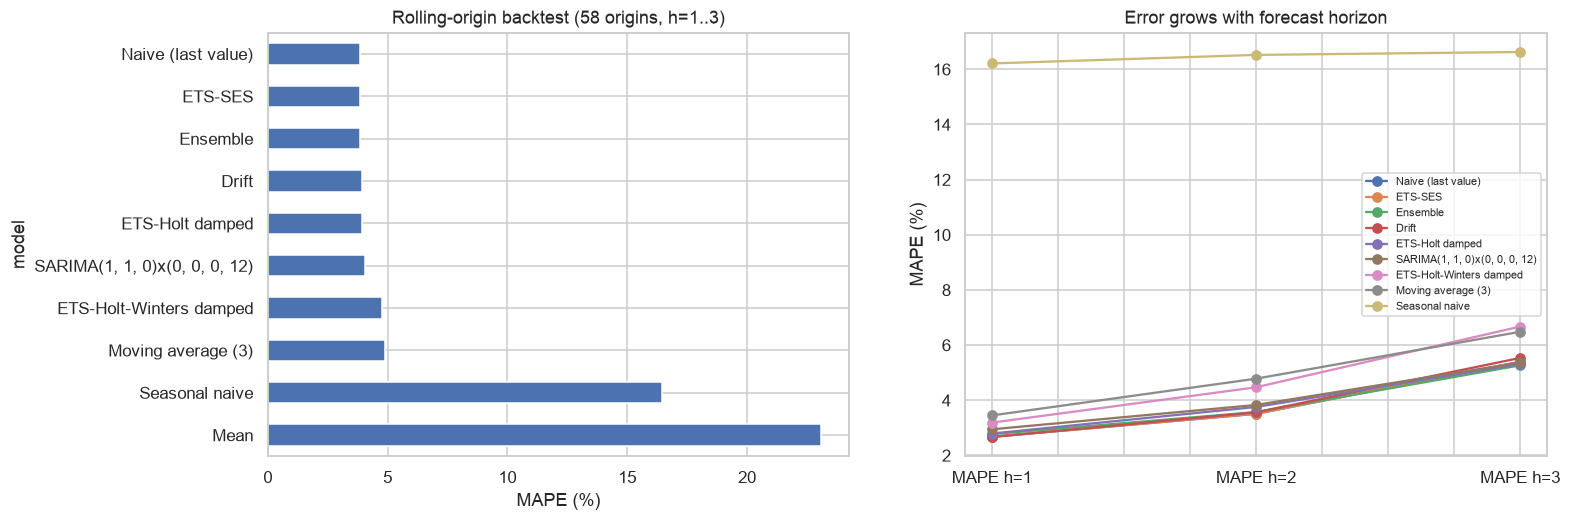

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bt_scores["MAPE"].sort_values().plot.barh(ax=axes[0], color="C0")
axes[0].set(title=f"Rolling-origin backtest ({len(origins)} origins, h=1..3)", xlabel="MAPE (%)")
axes[0].invert_yaxis()
by_h.drop(index="Mean").T.plot(ax=axes[1], marker="o")
axes[1].set(title="Error grows with forecast horizon", ylabel="MAPE (%)", xlabel="")
axes[1].legend(fontsize=7)
fig.savefig(FIG / "15_backtest_scores.png")
print("saved figures/15_backtest_scores.png")
plt.show()


## 12. SARIMA residual diagnostics (full sample)


In [34]:
final_sarima = SARIMAX(
    np.log(y), order=order, seasonal_order=sorder,
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
resid = final_sarima.resid[13:]

lb_res = acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True)
lb_res.round(4).to_csv(OUT / "09_sarima_residual_ljungbox.csv")
with open(OUT / "09_sarima_summary.txt", "w") as fh:
    fh.write(str(final_sarima.summary()))

print(final_sarima.summary())
print("\nLjung-Box on residuals:")
display(lb_res.round(4))


                                   SARIMAX Results                                   
Dep. Variable:     Rice (mixed, low quality)   No. Observations:                  285
Model:                      SARIMAX(1, 1, 0)   Log Likelihood                 484.696
Date:                       Sat, 17 Oct 2026   AIC                           -965.393
Time:                               23:14:04   BIC                           -958.102
Sample:                           01-01-2003   HQIC                          -962.469
                                - 09-01-2026                                         
Covariance Type:                         opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3053      0.043      7.088      0.000       0.221       0.390
sigma2         0.0019   9.53e-05     19.992      0.000       0.002       0.

,lb_stat,lb_pvalue
6,3.3000,0.7704
12,18.6031,0.0986
24,29.4736,0.2028


saved figures/16_sarima_residuals.png


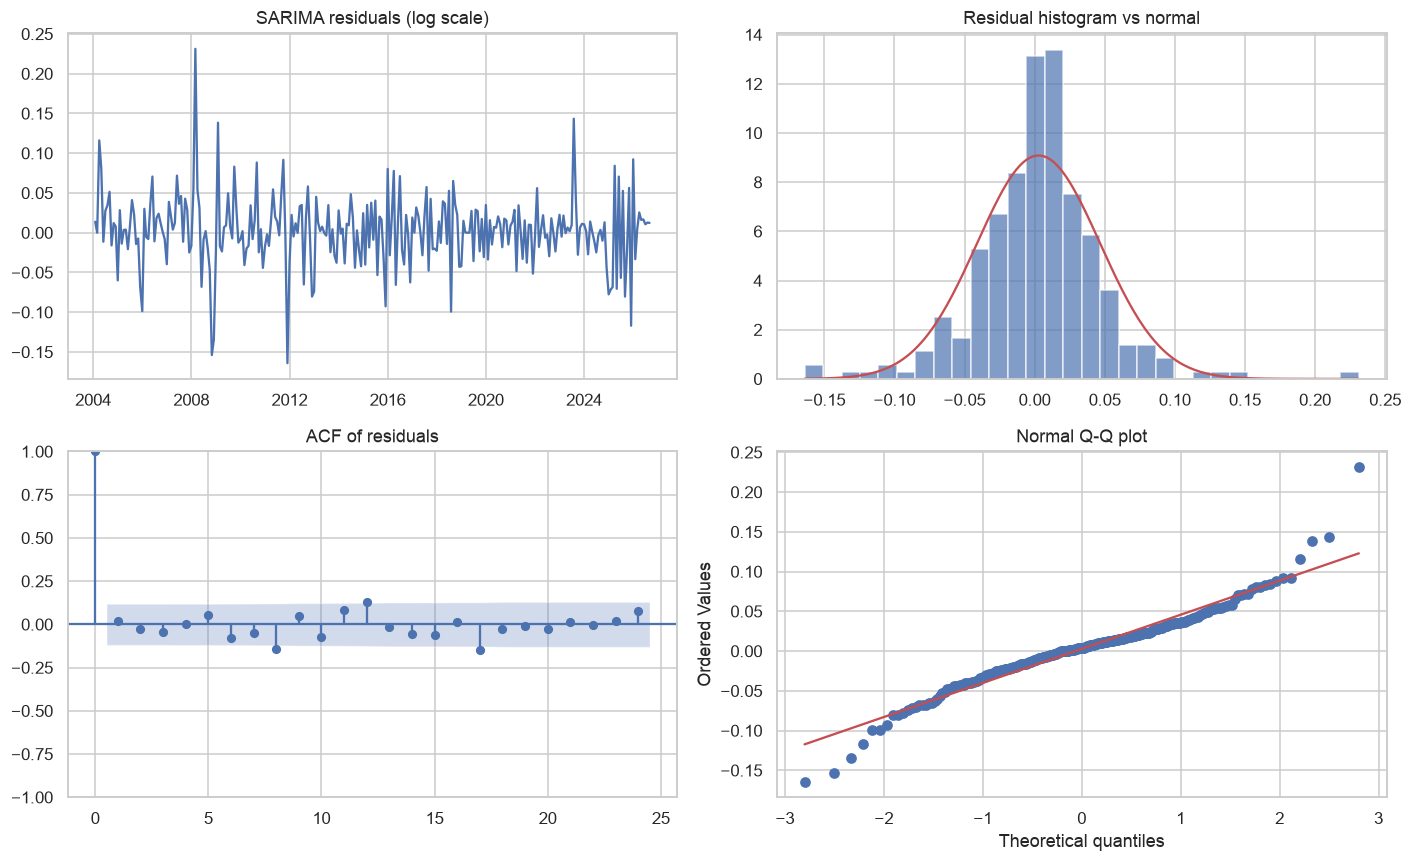

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(resid)
axes[0, 0].set_title("SARIMA residuals (log scale)")
axes[0, 1].hist(resid, bins=30, density=True, alpha=0.7)
xs = np.linspace(resid.min(), resid.max(), 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), "r")
axes[0, 1].set_title("Residual histogram vs normal")
plot_acf(resid, lags=24, ax=axes[1, 0], title="ACF of residuals")
stats.probplot(resid, plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.tight_layout()
fig.savefig(FIG / "16_sarima_residuals.png")
print("saved figures/16_sarima_residuals.png")
plt.show()


## 13. Final 3-month forecast (Oct–Dec 2026)


In [36]:
# Prediction intervals on log scale, then exp back
idx_fc = pd.date_range(y.index[-1], periods=H + 1, freq="MS")[1:]
ly_full = np.log(y)

# SARIMA
r = SARIMAX(
    ly_full, order=order, seasonal_order=sorder,
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
fc = r.get_forecast(H)
mu_s, se_s = fc.predicted_mean.values, fc.se_mean.values
fc_s = pd.DataFrame({
    "forecast": np.exp(mu_s),
    "lo80": np.exp(mu_s - Z80 * se_s),
    "hi80": np.exp(mu_s + Z80 * se_s),
    "lo95": np.exp(mu_s - Z95 * se_s),
    "hi95": np.exp(mu_s + Z95 * se_s),
}, index=idx_fc)

# ETS-Holt
r = ETSModel(ly_full, error="add", trend="add", damped_trend=True, seasonal=None).fit(disp=False, maxiter=2000)
pr = r.get_prediction(start=len(y), end=len(y) + H - 1)
mu_e = np.asarray(pr.predicted_mean)
se_e = np.sqrt(np.asarray(pr.var_pred_mean))
fc_e = pd.DataFrame({
    "forecast": np.exp(mu_e),
    "lo80": np.exp(mu_e - Z80 * se_e),
    "hi80": np.exp(mu_e + Z80 * se_e),
    "lo95": np.exp(mu_e - Z95 * se_e),
    "hi95": np.exp(mu_e + Z95 * se_e),
}, index=idx_fc)

# Naive
sig = ly_full.diff().dropna().std()
mu_n = np.repeat(ly_full.iloc[-1], H)
se_n = sig * np.sqrt(np.arange(1, H + 1))
fc_n = pd.DataFrame({
    "forecast": np.exp(mu_n),
    "lo80": np.exp(mu_n - Z80 * se_n),
    "hi80": np.exp(mu_n + Z80 * se_n),
    "lo95": np.exp(mu_n - Z95 * se_n),
    "hi95": np.exp(mu_n + Z95 * se_n),
}, index=idx_fc)

# Ensemble = geometric mean of the three forecasts / intervals
fc_ens = np.exp((np.log(fc_n) + np.log(fc_e) + np.log(fc_s)) / 3)

final = pd.concat(
    {"SARIMA": fc_s, "ETS-Holt damped": fc_e, "Naive": fc_n, "Ensemble": fc_ens},
    names=["model", "month"],
)
final.round(0).to_csv(OUT / "10_rice_wholesale_forecast.csv")
print("3-month wholesale rice forecast:")
display(final.round(0))


3-month wholesale rice forecast:


forecast    lo80    hi80    lo95    hi95
model           month                                               
SARIMA          2026-10-01    1910.0  1806.0  2020.0  1754.0  2081.0
                2026-11-01    1914.0  1745.0  2098.0  1662.0  2203.0
                2026-12-01    1915.0  1697.0  2160.0  1592.0  2303.0
ETS-Holt damped 2026-10-01    1918.0  1811.0  2031.0  1756.0  2094.0
                2026-11-01    1932.0  1765.0  2114.0  1683.0  2217.0
                2026-12-01    1943.0  1724.0  2190.0  1618.0  2333.0
Naive           2026-10-01    1900.0  1792.0  2015.0  1737.0  2078.0
                2026-11-01    1900.0  1749.0  2064.0  1674.0  2157.0
                2026-12-01    1900.0  1716.0  2103.0  1627.0  2219.0
Ensemble        2026-10-01    1909.0  1803.0  2022.0  1749.0  2084.0
                2026-11-01    1915.0  1753.0  2092.0  1673.0  2192.0
                2026-12-01    1919.0  1712.0  2151.0  1612.0  2285.0

saved figures/17_rice_forecast.png


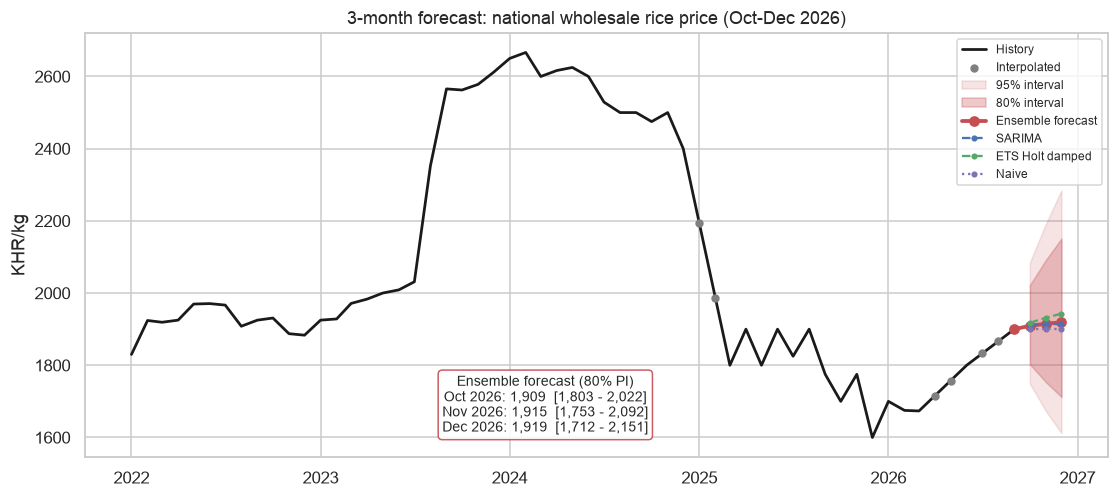

In [37]:
fig, ax = plt.subplots(figsize=(12, 5))
hist = y["2022":]
ax.plot(hist, color="k", lw=1.8, label="History")
ax.scatter(hist.index[imp["2022":]], hist[imp["2022":]], color="grey", s=20, zorder=5, label="Interpolated")
best = fc_ens
ax.fill_between(best.index, best.lo95, best.hi95, color="C3", alpha=0.15, label="95% interval")
ax.fill_between(best.index, best.lo80, best.hi80, color="C3", alpha=0.3, label="80% interval")
ax.plot(
    [y.index[-1], *best.index], [y.iloc[-1], *best.forecast],
    color="C3", lw=2.5, marker="o", label="Ensemble forecast",
)
ax.plot(fc_s.index, fc_s.forecast, ls="--", color="C0", marker=".", label="SARIMA")
ax.plot(fc_e.index, fc_e.forecast, ls="--", color="C2", marker=".", label="ETS Holt damped")
ax.plot(fc_n.index, fc_n.forecast, ls=":", color="C4", marker=".", label="Naive")
txt = "Ensemble forecast (80% PI)\n" + "\n".join(
    f"{d:%b %Y}: {r_.forecast:,.0f}  [{r_.lo80:,.0f} - {r_.hi80:,.0f}]" for d, r_ in best.iterrows()
)
ax.text(
    0.45, 0.05, txt, transform=ax.transAxes, ha="center", va="bottom", fontsize=9,
    bbox=dict(boxstyle="round", fc="white", ec="C3", alpha=0.9),
)
ax.set(title="3-month forecast: national wholesale rice price (Oct-Dec 2026)", ylabel="KHR/kg")
ax.legend(fontsize=8, loc="upper right")
fig.savefig(FIG / "17_rice_forecast.png")
print("saved figures/17_rice_forecast.png")
plt.show()


## 14. Food basket — retail prices & YoY inflation


In [38]:
base = P.loc["2020"].mean()
P["Food basket index"] = (100 * P / base).mean(axis=1)
P_imp["Food basket index"] = P_imp.any(axis=1)
P.round(1).to_csv(OUT / "11_retail_national_prices.csv")
print("Retail basket (last 6 months):")
display(P.tail(6).round(1))

fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for ax, c in zip(axes.flat, P.columns):
    ax.plot(P[c], lw=1.5)
    ax.plot(P[c].rolling(12, center=True).mean(), lw=2, color="C3", alpha=0.8)
    ax.set_title(c)
fig.suptitle("Retail food prices - national median (KHR) with 12-month moving average", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "18_basket_timeseries.png")
print("saved figures/18_basket_timeseries.png")
plt.show()


AttributeError: 'int' object has no attribute 'loc'

In [ ]:
yoy = (P["Food basket index"].pct_change(12) * 100).dropna()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yoy.index, yoy, width=25, color=np.where(yoy >= 0, "C3", "C0"))
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Food basket inflation (year-over-year %)", ylabel="%")
fig.savefig(FIG / "19_basket_yoy_inflation.png")
print("saved figures/19_basket_yoy_inflation.png")
plt.show()
print("Latest YoY inflation:")
display(yoy.tail(6).round(2))


## 15. Food basket — 3-month forecasts per commodity

Fits models for each retail series. This takes a few minutes.


In [ ]:
b_origins = pd.date_range("2024-03-01", "2026-06-01", freq="MS")
commodity_rows = []
commodity_fc = {}

for c in P.columns:
    s = P[c].copy()
    s.index.freq = "MS"
    o = ~P_imp[c]
    print(f"\n=== {c} ===")

    # small SARIMA grid on early sample
    grid_rows = []
    train0 = s[: b_origins[0]]
    for pp, qq, (P_, D_, Q_) in itertools.product(
        (0, 1), (0, 1), ((0, 0, 0), (1, 0, 0), (0, 0, 1))
    ):
        try:
            r = SARIMAX(
                np.log(train0), order=(pp, 1, qq), seasonal_order=(P_, D_, Q_, M),
                enforce_stationarity=False, enforce_invertibility=False,
            ).fit(disp=False)
            grid_rows.append({"order": (pp, 1, qq), "sorder": (P_, D_, Q_, M), "aic": r.aic})
        except Exception:
            pass
    gdf = pd.DataFrame(grid_rows).sort_values("aic").reset_index(drop=True)
    corder, csorder = gdf.loc[0, "order"], gdf.loc[0, "sorder"]

    # rolling backtest
    rows = []
    for origin in b_origins:
        tr = s[:origin]
        fut = pd.date_range(origin, periods=H + 1, freq="MS")[1:]
        preds = {
            "Naive": np.repeat(tr.iloc[-1], H),
            "Seasonal naive": np.array([tr.iloc[-M + (i % M)] for i in range(H)]),
        }
        r = ETSModel(np.log(tr), error="add", trend="add", damped_trend=True, seasonal=None).fit(disp=False, maxiter=2000)
        preds["ETS-Holt"] = np.exp(r.forecast(H).values)
        r = ETSModel(
            np.log(tr), error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=M
        ).fit(disp=False, maxiter=2000)
        preds["ETS-HW"] = np.exp(r.forecast(H).values)
        r = SARIMAX(
            np.log(tr), order=corder, seasonal_order=csorder,
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False)
        preds["SARIMA"] = np.exp(r.forecast(H).values)

        for name, fc in preds.items():
            for i, d in enumerate(fut):
                if d in s.index and o[d]:
                    rows.append({
                        "origin": origin, "model": name, "h": i + 1, "date": d,
                        "actual": s[d], "forecast": fc[i],
                    })

    cbt = pd.DataFrame(rows)
    sub = cbt[cbt.model.isin(["Naive", "ETS-Holt", "SARIMA"])]
    ens = sub.groupby(["origin", "h", "date", "actual"], as_index=False)["forecast"].mean()
    ens["model"] = "Ensemble"
    cbt = pd.concat([cbt, ens], ignore_index=True)

    sc_rows = []
    for name, g in cbt.groupby("model"):
        a = g.actual.values.astype(float)
        f = g.forecast.values.astype(float)
        e = a - f
        sc_rows.append({
            "model": name,
            "MAE": np.mean(np.abs(e)),
            "RMSE": np.sqrt(np.mean(e**2)),
            "MAPE": 100 * np.mean(np.abs(e / a)),
            "Bias": np.mean(e),
            "n": len(g),
        })
    sc = pd.DataFrame(sc_rows).set_index("model").sort_values("MAPE")
    best_name = sc.index[0]
    print(sc.round(2).to_string())
    print(f"Best model: {best_name}")

    # final forecast with PI
    idx_c = pd.date_range(s.index[-1], periods=H + 1, freq="MS")[1:]
    ly_c = np.log(s)

    # Naive PI
    sig = ly_c.diff().dropna().std()
    mu = np.repeat(ly_c.iloc[-1], H)
    se = sig * np.sqrt(np.arange(1, H + 1))
    fc_naive = pd.DataFrame({
        "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
        "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
    }, index=idx_c)

    # ETS-Holt PI
    r = ETSModel(ly_c, error="add", trend="add", damped_trend=True, seasonal=None).fit(disp=False, maxiter=2000)
    pr = r.get_prediction(start=len(s), end=len(s) + H - 1)
    mu = np.asarray(pr.predicted_mean)
    se = np.sqrt(np.asarray(pr.var_pred_mean))
    fc_holt = pd.DataFrame({
        "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
        "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
    }, index=idx_c)

    # ETS-HW / Seasonal naive / SARIMA used only if selected
    if best_name == "Seasonal naive":
        sig = (ly_c - ly_c.shift(M)).dropna().std()
        mu = np.log(np.array([s.iloc[-M + (i % M)] for i in range(H)]))
        se = sig * np.sqrt(np.floor(np.arange(H) / M) + 1)
        fc = pd.DataFrame({
            "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
            "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
        }, index=idx_c)
    elif best_name == "ETS-HW":
        r = ETSModel(
            ly_c, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=M
        ).fit(disp=False, maxiter=2000)
        pr = r.get_prediction(start=len(s), end=len(s) + H - 1)
        mu = np.asarray(pr.predicted_mean)
        se = np.sqrt(np.asarray(pr.var_pred_mean))
        fc = pd.DataFrame({
            "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
            "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
        }, index=idx_c)
    elif best_name == "ETS-Holt":
        fc = fc_holt
    elif best_name == "Naive":
        fc = fc_naive
    elif best_name == "SARIMA":
        r = SARIMAX(
            ly_c, order=corder, seasonal_order=csorder,
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False)
        fcx = r.get_forecast(H)
        mu, se = fcx.predicted_mean.values, fcx.se_mean.values
        fc = pd.DataFrame({
            "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
            "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
        }, index=idx_c)
    else:  # Ensemble
        r = SARIMAX(
            ly_c, order=corder, seasonal_order=csorder,
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False)
        fcx = r.get_forecast(H)
        mu, se = fcx.predicted_mean.values, fcx.se_mean.values
        fc_sar = pd.DataFrame({
            "forecast": np.exp(mu), "lo80": np.exp(mu - Z80 * se), "hi80": np.exp(mu + Z80 * se),
            "lo95": np.exp(mu - Z95 * se), "hi95": np.exp(mu + Z95 * se),
        }, index=idx_c)
        fc = np.exp((np.log(fc_naive) + np.log(fc_holt) + np.log(fc_sar)) / 3)

    commodity_fc[c] = fc
    commodity_rows.append({
        "commodity": c,
        "sarima": f"{corder}x{csorder}",
        "best_model": best_name,
        "best_MAPE": sc.loc[best_name, "MAPE"],
        "naive_MAPE": sc.loc["Naive", "MAPE"],
        "last_obs": s.iloc[-1],
        **{f"{d:%b %Y}": v for d, v in fc.forecast.items()},
        "change_to_dec_pct": 100 * (fc.forecast.iloc[-1] / s.iloc[-1] - 1),
    })

csum = pd.DataFrame(commodity_rows)
csum.round(2).to_csv(OUT / "12_basket_forecast_summary.csv", index=False)
pd.concat(commodity_fc, names=["commodity", "month"]).round(1).to_csv(OUT / "12_basket_forecast_intervals.csv")
print("\nBasket forecast summary:")
display(csum.round(2))


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, c in zip(axes.flat, P.columns):
    s = P[c]["2023":]
    fc = commodity_fc[c]
    ax.plot(s, color="k", lw=1.4)
    ax.fill_between(fc.index, fc.lo95, fc.hi95, color="C3", alpha=0.15)
    ax.fill_between(fc.index, fc.lo80, fc.hi80, color="C3", alpha=0.3)
    ax.plot([s.index[-1], *fc.index], [s.iloc[-1], *fc.forecast], color="C3", marker="o", lw=2)
    bm = csum.set_index("commodity").loc[c, "best_model"]
    ax.set_title(f"{c}  [{bm}]", fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.suptitle("3-month retail price forecasts (Oct-Dec 2026) with 80% / 95% intervals", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "20_basket_forecasts.png")
print("saved figures/20_basket_forecasts.png")
plt.show()


## 16. Province-level forecasts (top-down)


In [ ]:
last = y.index[-1]
window = pd.date_range(last - pd.DateOffset(months=23), last, freq="MS")

# national series + forecast frames to downscale
SHORT_MAIN = {"Rice (mixed, low quality)": "Rice"}
series_all = [
    (("Rice (mixed, low quality)", "Wholesale", "KG"), "Rice (wholesale)", y, final.loc["Ensemble"]),
]
for com, pt, unit, short in BASKET:
    series_all.append(((com, pt, unit), f"{short} (retail)", nat[short], commodity_fc[short]))

prov_rows = []
ratio_tbl = {}
for (com, pt, unit), label, nat_s, fc in series_all:
    sub = df[(df.commodity == com) & (df.pricetype == pt) & (df.unit == unit)]
    pm = sub.pivot_table(index="month", columns="admin1", values="price", aggfunc="median").reindex(window)
    ratios = pm.div(nat_s.reindex(window), axis=0)
    recent12 = ratios.iloc[-12:]
    ratio = recent12.median().where(recent12.notna().sum() >= 2, ratios.median())
    recent_obs = pm.loc[last - pd.DateOffset(months=6):].notna().any()
    ratio = ratio[(ratios.notna().sum() >= 2) & recent_obs]
    ratio_tbl[label] = ratio
    for prov, rt in ratio.items():
        last_seen = pm[prov].last_valid_index()
        for d, row in fc.iterrows():
            prov_rows.append({
                "series": label,
                "province": prov,
                "month": d.strftime("%Y-%m"),
                "relative_level": rt,
                "forecast": row.forecast * rt,
                "lo80": row.lo80 * rt,
                "hi80": row.hi80 * rt,
                "lo95": row.lo95 * rt,
                "hi95": row.hi95 * rt,
                "last_observed": last_seen.strftime("%Y-%m"),
                "last_price": pm.loc[last_seen, prov],
            })

prov_fc = pd.DataFrame(prov_rows)
prov_fc.round(2).to_csv(OUT / "13_province_forecasts.csv", index=False)
print("Province forecast rows:", len(prov_fc))
display(prov_fc.head(10))


In [ ]:
rt = pd.DataFrame(ratio_tbl)

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    (rt - 1) * 100, annot=True, fmt=".0f", cmap="RdYlGn_r", center=0, ax=ax,
    cbar_kws={"label": "% above / below national median"},
)
ax.set(title="Province price level relative to national median (Oct 2024 - Sep 2026)", ylabel="")
fig.savefig(FIG / "21_province_relative_prices.png")
print("saved figures/21_province_relative_prices.png")
plt.show()


In [ ]:
dec_month = window[-1].strftime("%Y") + "-12"
rice_dec = prov_fc[(prov_fc.series == "Rice (wholesale)") & (prov_fc.month == dec_month)]
coords = df.groupby("admin1")[["latitude", "longitude"]].mean()
rice_dec = rice_dec.join(coords, on="province").sort_values("forecast")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].barh(
    rice_dec.province, rice_dec.forecast,
    xerr=[rice_dec.forecast - rice_dec.lo80, rice_dec.hi80 - rice_dec.forecast],
    color="C1", alpha=0.8, capsize=2,
)
axes[0].axvline(final.loc["Ensemble"].forecast.iloc[-1], color="k", ls="--", label="National")
axes[0].set(
    title="Forecast wholesale rice price, Dec 2026 (80% interval)",
    xlabel="KHR/kg",
    xlim=(1200, rice_dec.hi80.max() * 1.03),
)
axes[0].legend()

sc_ = axes[1].scatter(
    rice_dec.longitude, rice_dec.latitude, c=rice_dec.forecast,
    s=rice_dec.forecast / 5, cmap="YlOrRd", edgecolor="k",
)
for _, r_ in rice_dec.iterrows():
    axes[1].annotate(
        r_.province, (r_.longitude, r_.latitude), fontsize=8,
        xytext=(4, 4), textcoords="offset points",
    )
plt.colorbar(sc_, ax=axes[1], label="KHR/kg")
axes[1].set(
    title="Geographic view (province centroids of WFP markets)",
    xlabel="Longitude", ylabel="Latitude",
)
fig.savefig(FIG / "22_province_rice_forecast.png")
print("saved figures/22_province_rice_forecast.png")
plt.show()

pd.DataFrame([{
    "sarima_order": str(order),
    "seasonal_order": str(sorder),
    **strength,
    "last_month": str(y.index[-1].date()),
    "last_price": y.iloc[-1],
}]).to_csv(OUT / "99_key_facts.csv", index=False)
print("Done. Key facts saved to outputs/99_key_facts.csv")
